# 6. Spatial correlation and where to place samples
> Gaussian random fields as synthetic contamination, and how random, stratified, systematic and clustered placement within a unit change what samples tell us

Background for the temporary series on the `scoring-experiments` branch:

0. A primer on Bayesian statistics, for trufl
1. A sampling campaign, round by round
2. The MCDM layer
3. What a good campaign means
4. The sawtooth in the restriction rule
5. From `bayes` to `voi`
6. Spatial correlation and where to place samples (this notebook)

Notebooks 0 to 5 decide how many samples each unit gets. This one is about where the samples go inside a unit. The results behind it are in "Placement within a unit" in `_scoring_experiments.ipynb` and in `scoring-design.md`.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.spatial.distance import pdist
from scipy.cluster.vq import kmeans2

## Why spatial correlation

Contamination after an accident is not scattered cell by cell. A plume deposits more where it passed and where it rained, so neighbouring fields have similar values and distant ones less so. This is spatial correlation: the closer two places, the more alike their values.

To test sampling strategies, we need fields with this property whose truth we know completely. Gaussian random fields are the simplest such model.

## A Gaussian random field

A Gaussian random field gives every cell a value such that any set of cells has a joint normal distribution. With a mean of 0 and a variance of 1, it is defined by one function: the correlation between two cells as a function of the distance `h` between them. The distance over which the correlation fades is the range.

The simplest way to make one is to smooth white noise. White noise gives each cell an independent normal value, so it has no correlation at all. A Gaussian filter of width `sigma` replaces each cell by a weighted average of the noise around it. Two cells closer than a few `sigma` average over much of the same noise, so they get similar values. Two cells far apart average over different noise, so they stay independent.

In [ ]:
def grf(sigma, rng, N=128):
    "An `N` by `N` Gaussian random field with mean 0 and variance 1, white noise smoothed with width `sigma` cells."
    z = rng.standard_normal((N, N))
    f = gaussian_filter(z, sigma, mode='wrap') if sigma > 0 else z
    return (f - f.mean()) / f.std()

`mode='wrap'` treats the grid as a torus, so cells at the edges are smoothed like the others. The last line rescales the field to a mean of 0 and a variance of 1, because smoothing shrinks the variance. Three fields from the same noise, with increasing `sigma`:

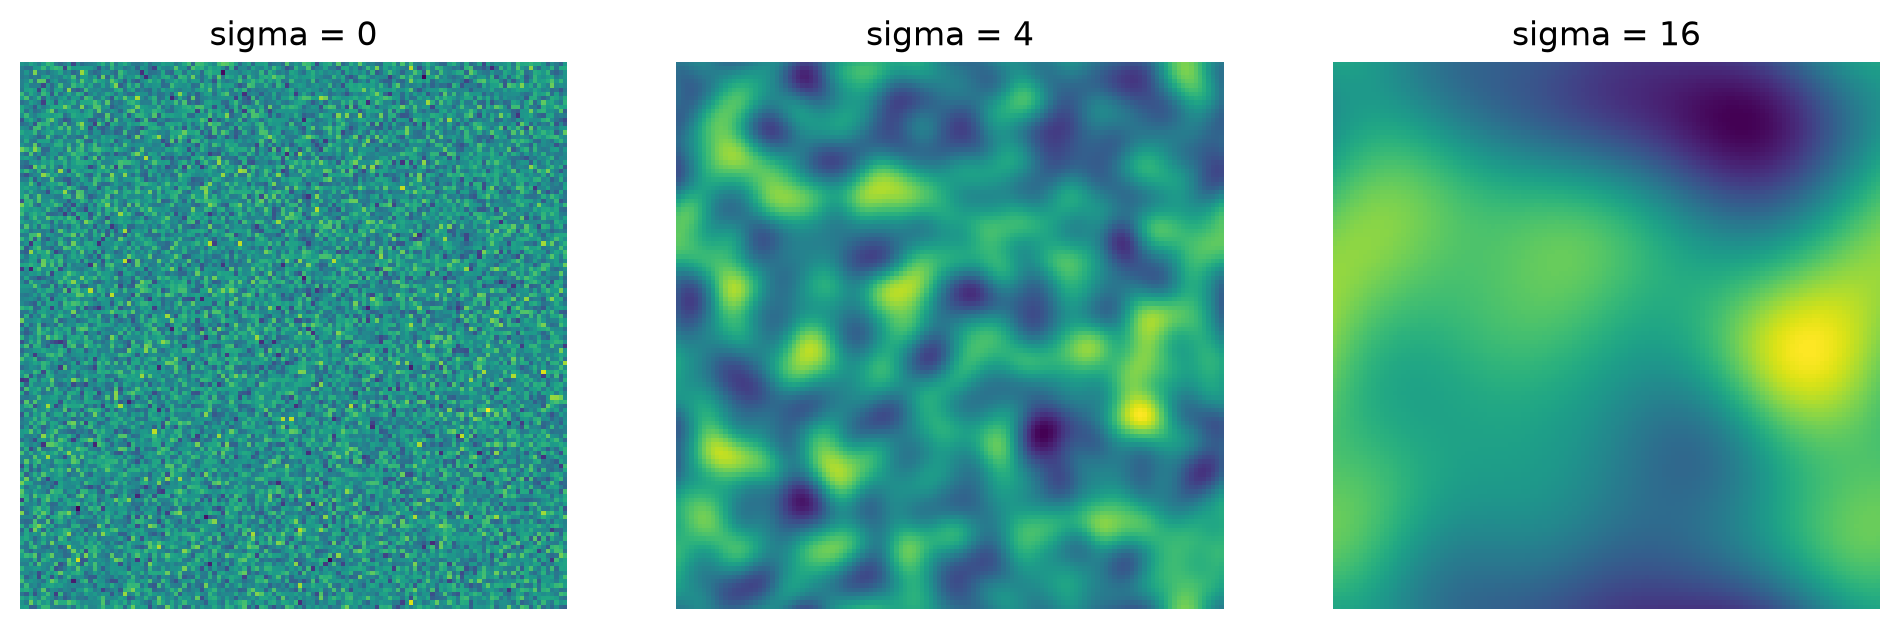

In [ ]:
rng = np.random.default_rng(0)
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, s in zip(axs, [0, 4, 16]):
    ax.imshow(grf(s, np.random.default_rng(0)), cmap='viridis'); ax.set_title(f'sigma = {s}'); ax.axis('off')

With `sigma` 0 it is pure noise. With 4, small patches appear. With 16, the patches are about as wide as a quarter of the grid.

Smoothing with a Gaussian of width `sigma` gives a correlation of exp(-h² / 4 sigma²) at distance `h`. The check below measures it on large fields, so that the finite grid does not bias it, and compares with the formula:

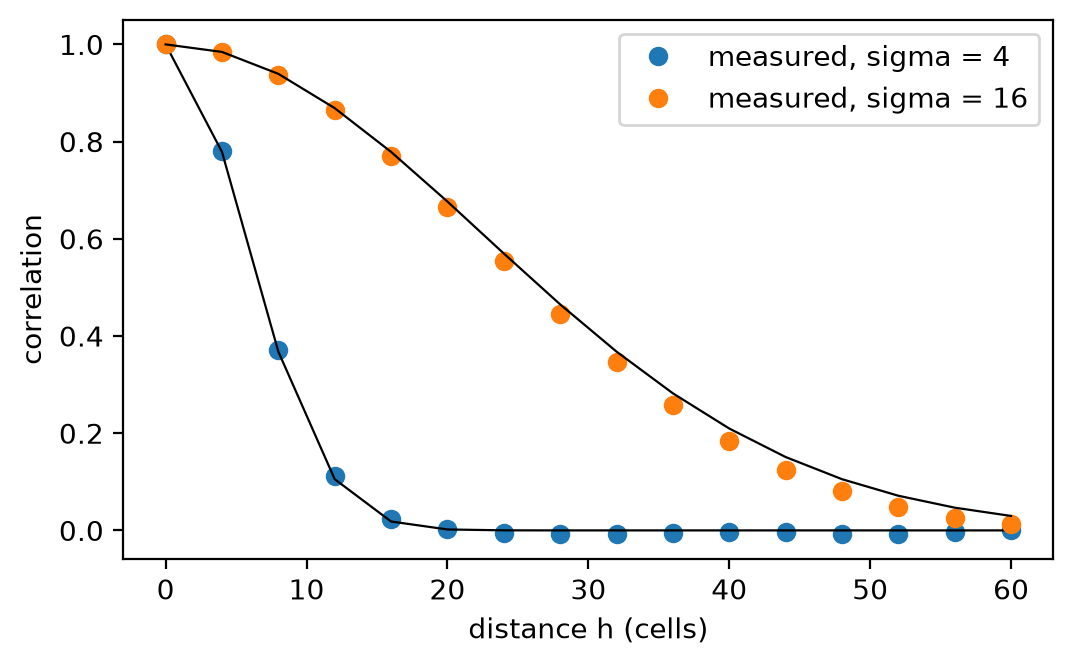

In [ ]:
def corr_at(sigma, lags, reps=10, N=512, seed=0):
    "Correlation between cells `lags` apart along a row, averaged over `reps` fields."
    rng = np.random.default_rng(seed); out = np.zeros(len(lags))
    for _ in range(reps):
        f = grf(sigma, rng, N)
        out += [np.mean(f * np.roll(f, h, axis=1)) for h in lags]
    return out / reps

lags = np.arange(0, 61, 4)
fig, ax = plt.subplots(figsize=(6, 3.5))
for s in [4, 16]:
    c = corr_at(s, lags)
    ax.plot(lags, c, 'o', label=f'measured, sigma = {s}'); ax.plot(lags, np.exp(-lags**2 / (4 * s**2)), 'k-', lw=0.8)
    assert np.abs(c - np.exp(-lags**2 / (4 * s**2))).max() < 0.05
ax.set_xlabel('distance h (cells)'); ax.set_ylabel('correlation'); ax.legend();

The correlation falls to about 5% at h = 3.5 sigma: 14 cells for `sigma` 4 and 56 cells for `sigma` 16. On a unit of 128 cells, the first field holds many independent patches and the second only a few.

Smoothing gives this Gaussian-shaped correlation only. Geostatistics also uses exponential and Matérn correlations, which are rougher at short distances; they are made by filtering the noise in Fourier space instead. For sampling questions, the range compared with the size of the unit matters most, so smoothing is enough here.

Measured contamination is closer to lognormal than normal. `np.exp(a + b * grf(...))` gives a lognormal field with the same pattern. Since the level below is set by a quantile, the share above it and every result in this notebook stay the same under that transform.

## A contaminated unit

Take the whole grid as one unit. Setting the level at the 90% quantile of the field makes exactly 10% of the unit's area exceed it, so the truth trufl wants to know, `share`, is fixed and known:

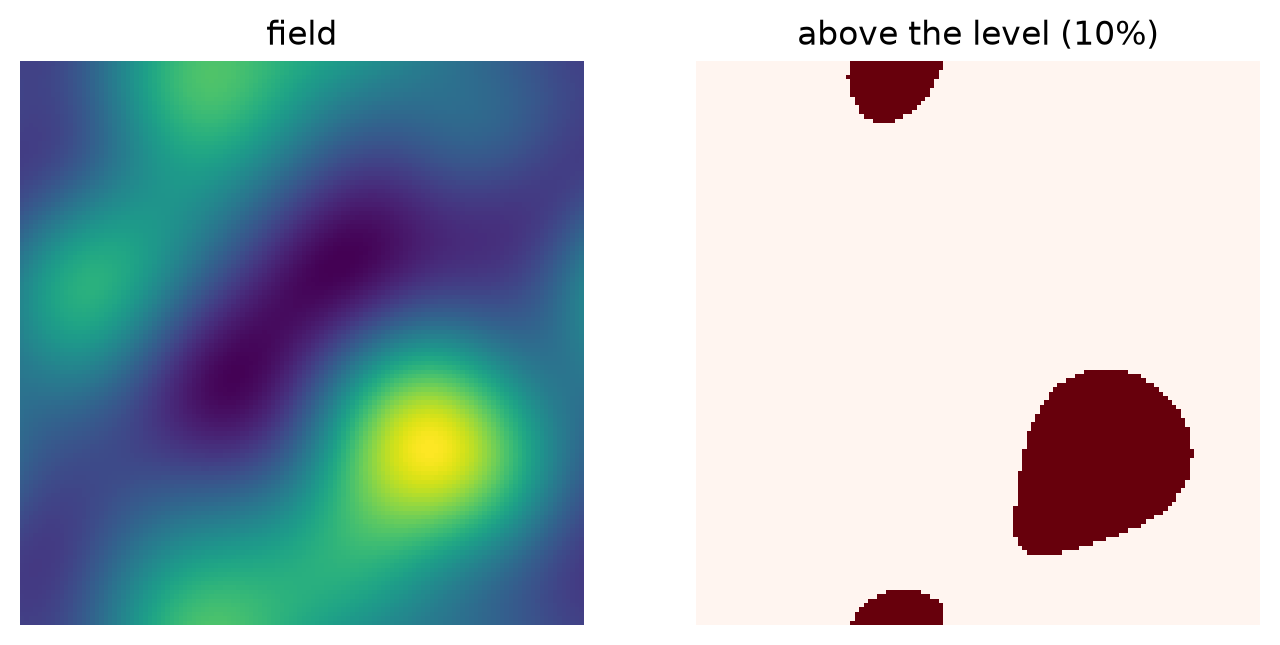

In [ ]:
p = 0.10
f = grf(16, np.random.default_rng(3))
level = np.quantile(f, 1 - p)
above = f > level
assert abs(above.mean() - p) < 1e-3
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
axs[0].imshow(f, cmap='viridis'); axs[0].set_title('field')
axs[1].imshow(above, cmap='Reds'); axs[1].set_title('above the level (10%)')
for ax in axs: ax.axis('off')

With correlation, the 10% above the level forms a few patches instead of scattered cells. Where samples land relative to the patches now matters.

## Four placements

Each placement returns the row and column of `n` samples in an `N` by `N` unit:

- Random: each sample is a uniform random cell, independently of the others.
- Stratified: cut the unit into `n` equal blocks and draw one random cell in each. The samples are spread out, but each is still random within its block.
- Systematic: a regular grid of `n` points, shifted as a whole by one random offset. The spacing is fixed; only the offset is random.
- Clustered: samples gathered around 4 random centres, as when teams sample along roads or at one farm.

In [ ]:
def place(design, n, rng, N=128):
    "Row and column of `n` samples placed by `design` in an `N` by `N` unit; `n` must be a square for the grid designs."
    if design == 'random': return rng.integers(0, N, (n, 2))
    s = int(round(np.sqrt(n))); w = N / s
    gi, gj = np.meshgrid(np.arange(s), np.arange(s)); g = np.c_[gi.ravel(), gj.ravel()]
    if design == 'stratified': return np.floor((g + rng.random((n, 2))) * w).astype(int)
    if design == 'systematic': return np.floor((g + rng.random(2)) * w).astype(int)
    if design == 'clustered':
        c = rng.integers(0, N, (4, 2))
        return (c[np.arange(n) % 4] + rng.integers(-6, 7, (n, 2))) % N

designs = ['random', 'stratified', 'systematic', 'clustered']

In stratified placement, `g` holds the block indices and `rng.random((n, 2))` a separate position inside each block. In systematic placement, `rng.random(2)` is one offset shared by all points. Thirty-six samples of each placement on the unit above:

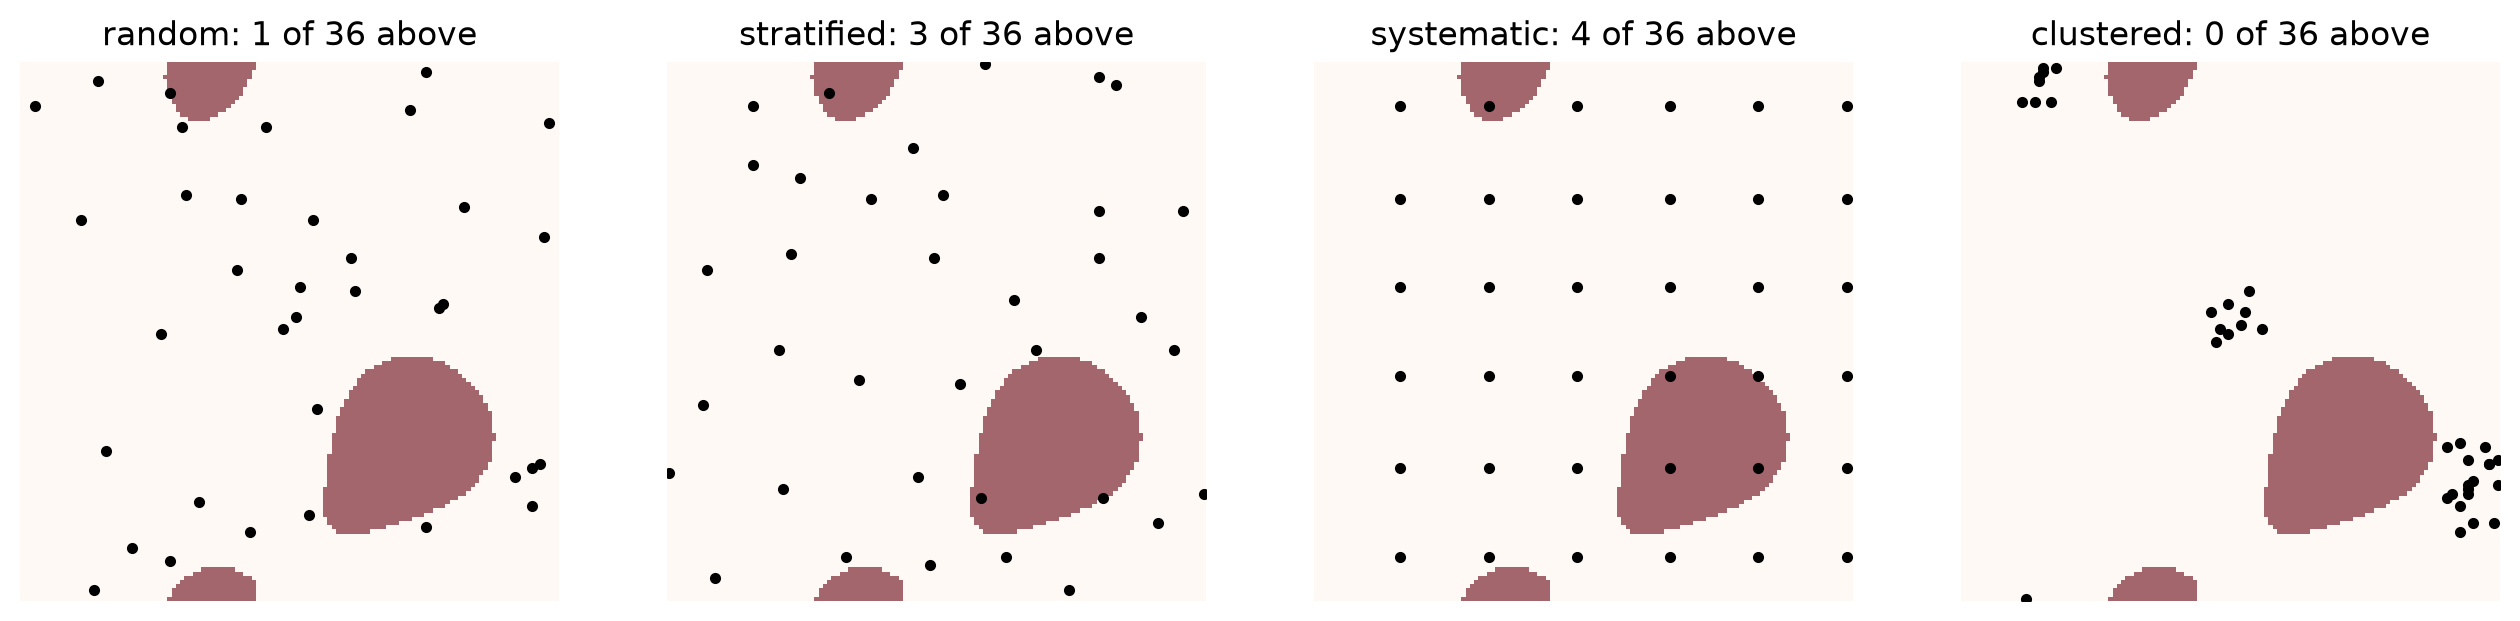

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, d in zip(axs, designs):
    xy = place(d, 36, np.random.default_rng(1))
    k = above[xy[:, 0], xy[:, 1]].sum()
    ax.imshow(above, cmap='Reds', alpha=0.6); ax.plot(xy[:, 1], xy[:, 0], 'k.', ms=6)
    ax.set_title(f'{d}: {k} of 36 above'); ax.axis('off')

Random samples can leave gaps and pile up elsewhere by chance. Stratified and systematic samples cover the unit evenly, so each patch gets about as many samples as its area deserves. Clustered samples see four places only.

## Why random placement keeps the binomial model

For random placement, each sample lands above the level with probability `share`, the fraction of the unit's area above it, whatever the pattern of the field. The samples are independent because the points are drawn independently, not because the field is uncorrelated. Survey statistics calls this design-based inference. It is why `bayes` and `voi` use a binomial model, and why that model is exact for random placement even on a correlated field.

Spread placements break the independence on purpose, in a useful direction: two samples are never close, so they rarely repeat each other's information. Clustered placement breaks it in the harmful direction: samples in one cluster mostly repeat each other.

## How much each placement tells

Repeat the experiment on many fields: draw a field with a true `share` of 10%, place `n` samples, count the samples above the level. The spread of `k / n` around 0.10 shows how well each placement estimates `share`:

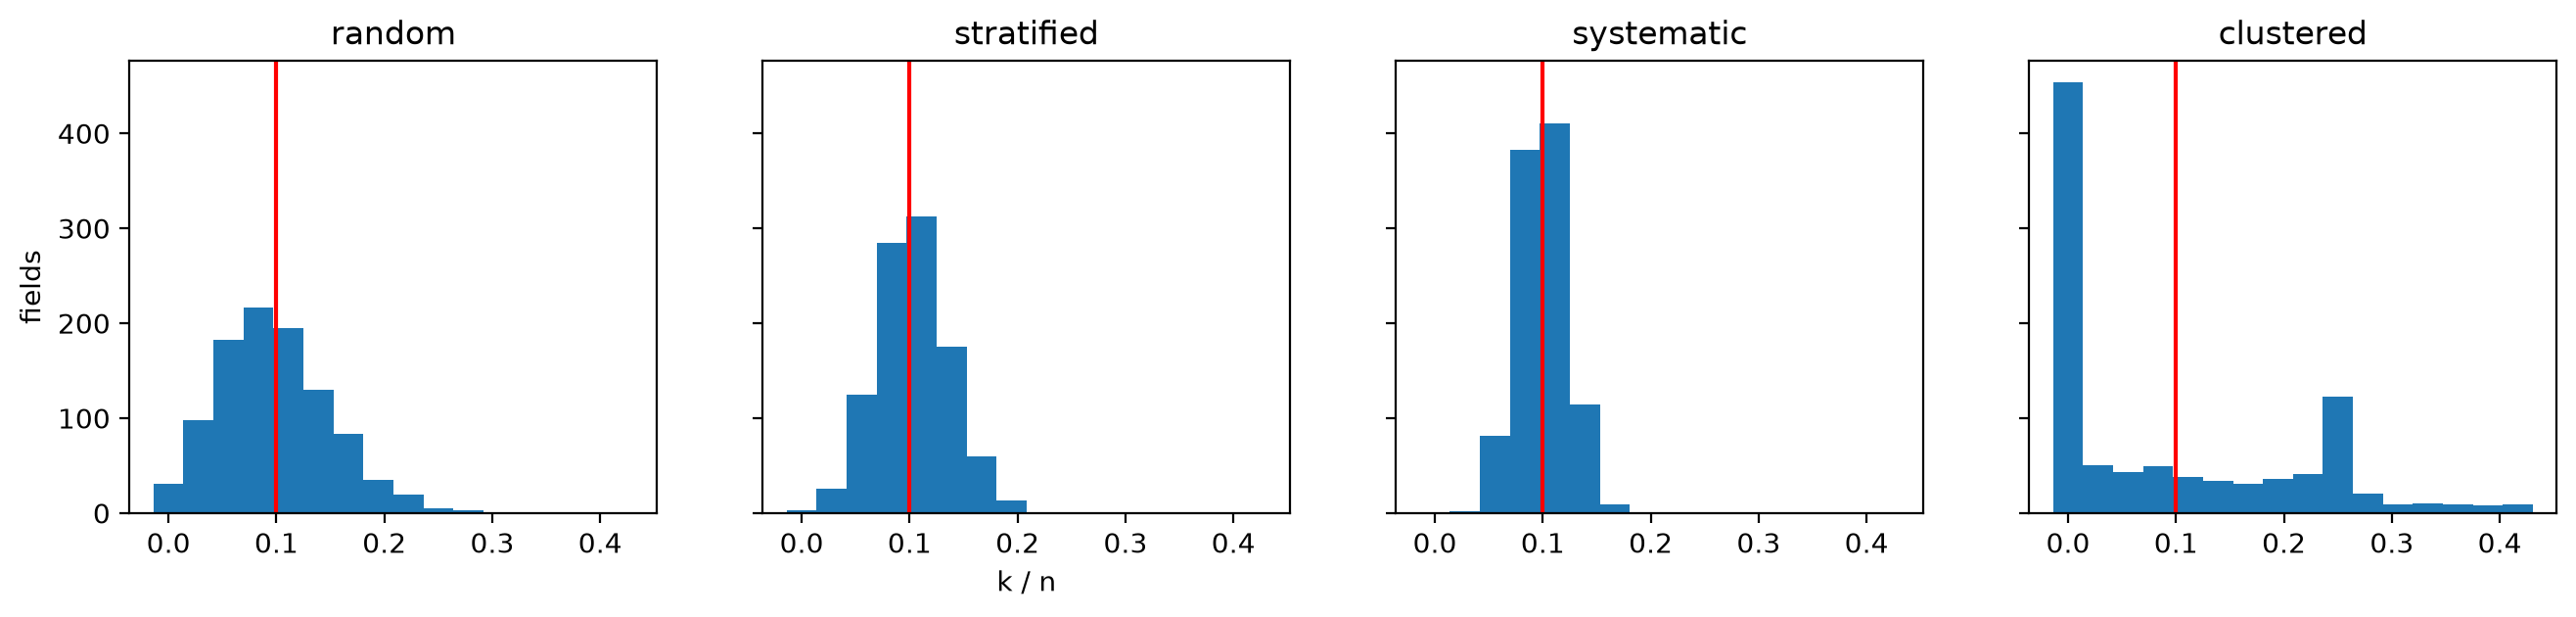

In [ ]:
def exceedances(sigma, p, design, n, reps=1000, seed=0):
    "Number of samples above the level in `reps` fields with a true share `p` above it."
    rng = np.random.default_rng(seed); k = np.empty(reps)
    for r in range(reps):
        f = grf(sigma, rng); lvl = np.quantile(f, 1 - p)
        xy = place(design, n, rng); k[r] = (f[xy[:, 0], xy[:, 1]] > lvl).sum()
    return k

n = 36
ks = {d: exceedances(16, p, d, n) for d in designs}
fig, axs = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, d in zip(axs, designs):
    ax.hist(ks[d] / n, bins=np.arange(-0.5, 16.5) / n, color='C0'); ax.axvline(p, color='r'); ax.set_title(d)
axs[0].set_ylabel('fields'); axs[1].set_xlabel('k / n');

The effective sample size turns a spread into a sample count: the number of random samples that would give the same variance. Random samples give p(1 - p) / n, so a placement with variance `var` is worth p(1 - p) / `var` random samples:

In [ ]:
n_eff = {d: p * (1 - p) / (ks[d] / n).var() for d in designs}
pd.Series(n_eff).round(0)

random         34.0
stratified     77.0
systematic    167.0
clustered       5.0
dtype: float64

In [ ]:
assert 25 < n_eff['random'] < 50
assert n_eff['systematic'] > 3 * n
assert n_eff['clustered'] < n / 4

With `sigma` 16, the 36 random samples are worth about 36, as the binomial model says. The 36 stratified samples are worth about twice as many, the 36 systematic ones more than four times as many, and the 36 clustered ones only a handful. `_scoring_experiments.ipynb` repeats this for other `sigma` and `n`: without correlation all placements are the same, and the gain from spreading grows with the range.

## Systematic or stratified

Systematic placement gained most here, but it has two weaknesses:

- Periodic patterns. If the field repeats with a period close to the grid spacing (terraces, rows of a crop, drainage lines), every point can fall on the same phase, and the estimate is biased. Stratified placement draws each point independently within its block, so it cannot lock onto a period.
- Uncertainty. With one random offset, a systematic sample has no unbiased estimate of its own variance. Treating it as random (binomial) is safe, because it overstates the uncertainty.

Stratified placement keeps part of the gain (77 against 167 here) and avoids both. It is the safer default when the field may have a period; systematic placement is the better one when it can't.

## Units that are not squares

Real units are municipalities or fields, not squares. Two simple ways to spread samples over any shape, given the cells inside the unit:

- Systematic: lay a regular grid with a random offset over the bounding box, and keep the points inside the unit. The number of points varies with the offset and the shape.
- Stratified: cut the unit's cells into `n` compact strata of similar size with k-means on their coordinates, and draw one random cell in each.

In [ ]:
N = 128
rows, cols = np.mgrid[:N, :N]
inside = ((cols - 60) / 55)**2 + ((rows - 64) / 35)**2 < 1
cells = np.c_[rows[inside], cols[inside]]

def stratified_in(cells, n, rng):
    "One random cell in each of `n` k-means strata of `cells`."
    _, lab = kmeans2(cells.astype(float), n, seed=rng, minit='++')
    return np.array([cells[rng.choice(np.flatnonzero(lab == j))] for j in range(n)]), lab

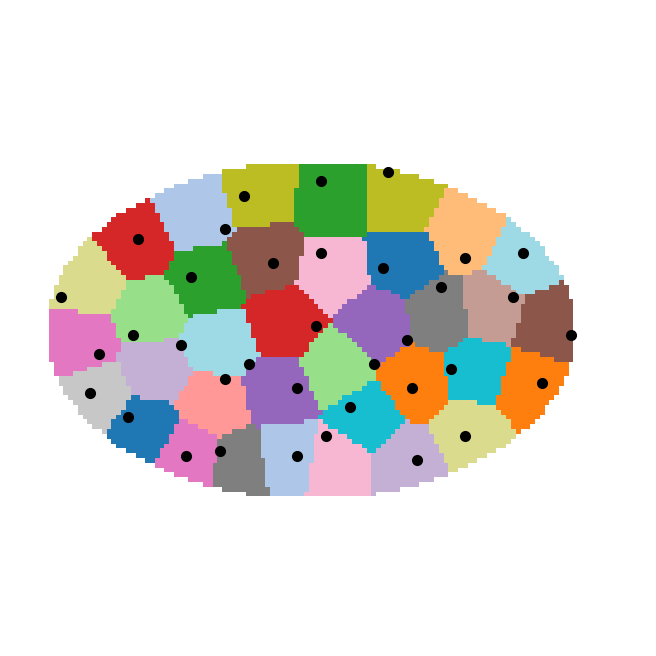

In [ ]:
rng = np.random.default_rng(2)
xy, lab = stratified_in(cells, 36, rng)
strata = np.full((N, N), np.nan); strata[inside] = lab
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(strata, cmap='tab20', interpolation='nearest'); ax.plot(xy[:, 1], xy[:, 0], 'k.', ms=6); ax.axis('off');

Each colour is a stratum; each has one sample. For a large unit, k-means on every cell is slow; running it on a random subset of cells gives the same strata. Spatially balanced designs such as GRTS (generalised random tessellation stratified) do the same job with more guarantees, and are used in environmental monitoring.

## Estimating the range: variogram and Moran's I

How much spreading gains depends on the range compared with the unit. The usual estimate is a variogram: for each pair of samples, half the squared difference of their values, averaged in bins of distance. Close pairs have small differences when the range is long; beyond the range the semivariance levels off at the variance. Here are variograms from 64 random samples on five fields each, for two ranges:

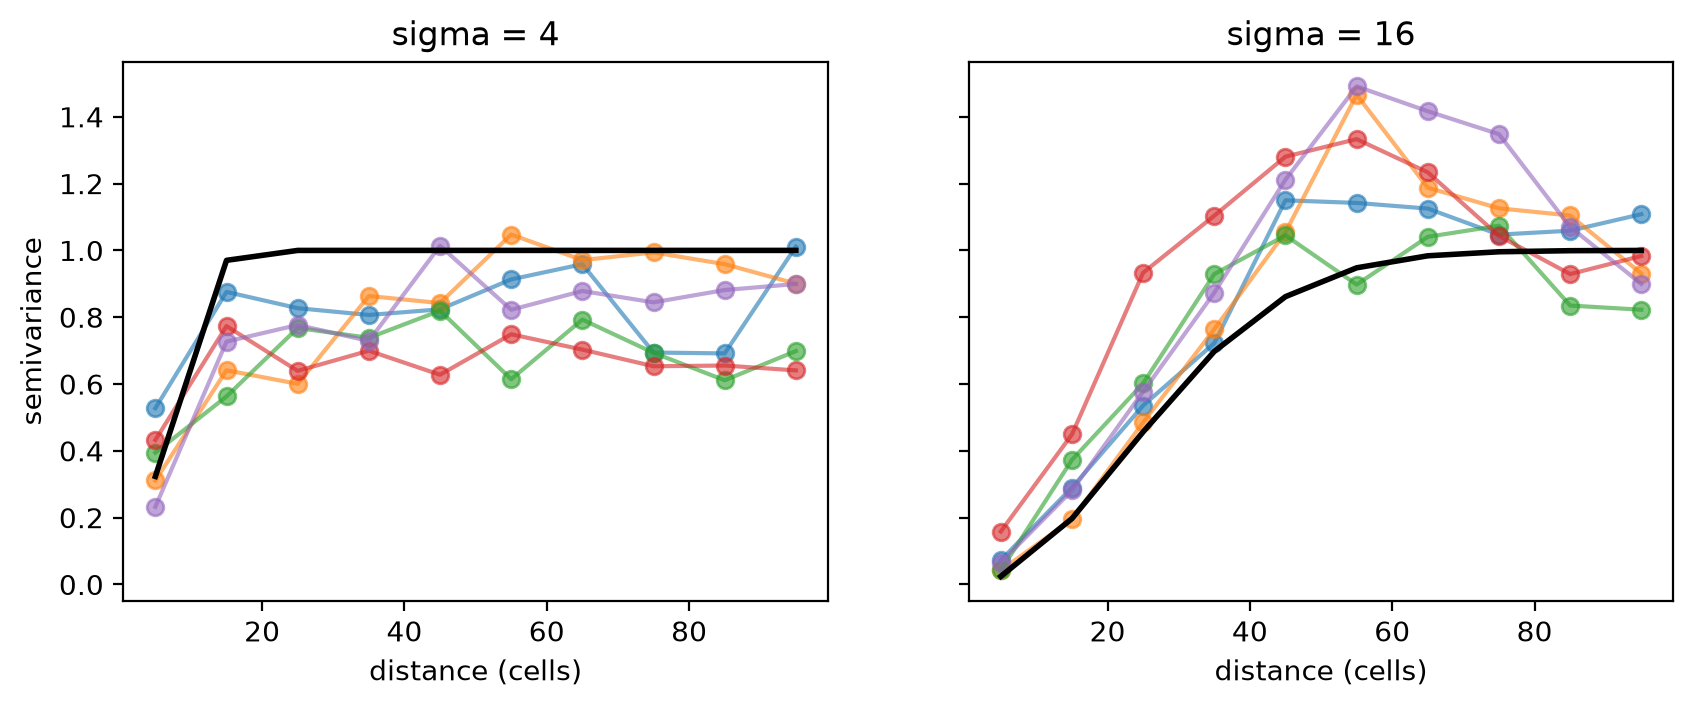

In [ ]:
def variogram(xy, z, bins):
    "Mean of half the squared difference of `z` over pairs of points in each distance bin."
    d, g = pdist(xy), 0.5 * pdist(z[:, None], 'sqeuclidean')
    i = np.digitize(d, bins)
    return np.array([g[i == j].mean() for j in range(1, len(bins))])

bins = np.arange(0, 101, 10); mids = bins[:-1] + 5
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, s in zip(axs, [4, 16]):
    rng = np.random.default_rng(1)
    for _ in range(5):
        f = grf(s, rng); xy = place('random', 64, rng)
        ax.plot(mids, variogram(xy, f[xy[:, 0], xy[:, 1]], bins), 'o-', alpha=0.6)
    ax.plot(mids, 1 - np.exp(-mids**2 / (4 * s**2)), 'k-', lw=2)
    ax.set_title(f'sigma = {s}'); ax.set_xlabel('distance (cells)')
axs[0].set_ylabel('semivariance');

With `sigma` 4, the semivariance is near its plateau from the first bin: samples more than 10 cells apart are nearly independent. With `sigma` 16, it climbs over about 40 cells. Sixty-four samples separate the two cases, but each curve is noisy, so the range from one unit is rough; pooling neighbouring units, or reading the scale from the prior raster, would do better.

Moran's I, which `MoranICB` computes, tests whether nearby samples are more alike than distant ones. It answers whether there is correlation, not over what distance, so it cannot say how much spreading gains.

## What this means for trufl

- Placement within a unit is a choice as important as the number of samples per unit, once the field is correlated. Stratified placement costs no extra samples, and is the safer default.
- The binomial model behind `bayes` and `voi` is exact for random placement, cautious for spread placement and overconfident for clustered placement. Clustered placement is the dangerous case in practice: many samples, little information, and errors that are mostly missed restrictions.
- Taking placement into account in `voi` would mean an effective sample count per unit, set by the placement and by the range compared with the unit size.
- When the range is long, the exceedances form patches. That makes "partially restrict" meaningful, and placing extra samples near the first exceedances a way to map the patch.

`scoring-design.md` records these as proposals under "Placement within a unit".